# Market Basket Analysis
## CA2 Mini Project — Data Mining and Business Intelligence

**Objective:** Identify frequent grocery product combinations, evaluate association rules, and demonstrate an explainable basket recommender. This implements the same retail problem analysed in CA1.

**Dataset:** [Groceries Market Basket Dataset on Kaggle](https://www.kaggle.com/datasets/irfanasrullah/groceries), with 9,835 baskets and 169 categories. Use this specific dataset; a customer/date grocery table needs different transaction reconstruction.

**Run instructions**
1. Put this notebook in `CA1_CA2_Market_Basket_Analysis/`. Keep the Kaggle CSV/ZIP available to select when prompted; it may be stored in `Dataset/` for submission.
2. Open the notebook and select **Restart Kernel and Run All Cells**. The import step always asks you to select a Kaggle CSV or ZIP. Colab uses **Choose Files**; local Jupyter uses a file dialog or a full-path prompt.
3. Initial dependency installation requires internet. Data is read from your local file; no API key or embedded/synthetic fallback is used.
4. Inspect `Results/` after execution. The original dataset is not overwritten. Saved tables/charts show the tested run; rerun to regenerate them in your environment.

**Workflow:** Problem → Data → Preprocessing → Algorithm → Results → Evaluation → Insights → Decision.

Every code cell below has a preceding description explaining its purpose, operations and expected output. Warning output is suppressed for readability; genuine failures remain visible. Runtime measurements can differ between computers.


## Step 1 — Environment and project configuration

**Purpose:** Load the analysis libraries, record versions, and define the common parameters. Only missing packages are installed; existing packages are not unnecessarily replaced.

**What the code does:** `MIN_SUPPORT = 0.01` sets 1% support; `MIN_CONFIDENCE = 0.25` sets 25% confidence. `SEED = 42` makes the random split repeatable. The notebook always asks you to select the input dataset and creates `Results/` in the working project directory. It does not search dataset folders. Warning messages are suppressed for readable output; execution errors are not hidden.

**Expected output and interpretation:** A package-version table and the location of `Results/`. An initial package installation needs internet.

**Jupyter compatibility:** Before any upload, repair the deprecated timestamp helper only in older Jupyter clients. The replacement returns timezone-aware UTC, matching modern Jupyter behaviour. Installed package files are not modified, and no kernel-package upgrade is required.

In [1]:
# Clean presentation output: suppress warnings, not execution errors.
import os, warnings, logging
warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
os.environ["PIP_DISABLE_PIP_VERSION_CHECK"] = "1"
os.environ["PIP_ROOT_USER_ACTION"] = "ignore"
logging.getLogger("jupyter_client").setLevel(logging.ERROR)

# Compatibility repair for older Jupyter clients on Python 3.12/3.13+.
# Apply the modern timezone-aware timestamp operation only when the old
# function calls datetime.utcnow(). This changes the running session only.
from datetime import datetime as _datetime, timezone as _timezone
import importlib as _importlib

def _repair_jupyter_utc_clock():
    try:
        _session = _importlib.import_module("jupyter_client.session")
    except ImportError:
        return False  # Not needed in environments without jupyter_client.
    _previous = getattr(_session, "utcnow", None)
    _names = getattr(getattr(_previous, "__code__", None), "co_names", ())
    if not callable(_previous) or "utcnow" not in _names:
        return False  # Modern clients already use the supported operation.
    def _aware_utcnow():
        return _datetime.now(_timezone.utc)
    _session.utcnow = _aware_utcnow
    # Preserve equivalent imported references when present.
    try:
        _jsonutil = _importlib.import_module("jupyter_client.jsonutil")
    except ImportError:
        _jsonutil = None
    if _jsonutil is not None and getattr(_jsonutil, "utcnow", None) is _previous:
        _jsonutil.utcnow = _aware_utcnow
    return True

_JUPYTER_CLOCK_REPAIRED = _repair_jupyter_utc_clock()

import sys, subprocess, importlib.util, importlib.metadata, platform, json, io, csv
from pathlib import Path
from time import perf_counter
from math import ceil

# Tested run: mlxtend 0.25.0, pandas 3.1.0, NumPy 2.3.5, matplotlib 3.10.8.
# Other installed versions can work; the notebook checks key API compatibility.
required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "mlxtend": "mlxtend==0.25.0"}
missing = [spec for module, spec in required.items()
           if importlib.util.find_spec(module) is None]
if missing:
    print("Installing missing packages:", missing)
    installation = subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        capture_output=True, text=True)
    if installation.returncode != 0:
        raise RuntimeError("Package setup failed. Check internet access and retry.\n" + installation.stderr[-1500:])
    print("Required packages installed successfully.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import inspect

SEED = 42
MIN_SUPPORT = 0.01
MIN_CONFIDENCE = 0.25
# Export under the working project folder; input is always selected by the user.
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / "Results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
VERSIONS = {name: importlib.metadata.version(name) for name in required}
VERSIONS["python"] = platform.python_version()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 15)
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white",
                     "text.color": "black", "axes.labelcolor": "black",
                     "axes.edgecolor": "black", "xtick.color": "black",
                     "ytick.color": "black", "font.size": 10,
                     "savefig.facecolor": "white", "figure.dpi": 110})
display(pd.Series(VERSIONS, name="Version").to_frame())
print("Output folder:", OUTPUT_DIR.resolve())

Output folder: /workspace/scratch/5db1f46b376e/tmp/market_basket/submission_check/CA1_CA2_Market_Basket_Analysis/Results


,Version
numpy,2.3.5
pandas,3.1.0
matplotlib,3.10.8
mlxtend,0.25.0
python,3.12.14


## Step 2 — Import the Kaggle dataset

**Purpose:** Read the downloaded Groceries Market Basket Dataset and verify that the file matches this case study.

**What the code does:** Always ask for one CSV or ZIP: Colab opens an upload picker; local Jupyter opens a file dialog or asks for a path. This prompt appears on every run, even if dataset files already exist in the working folder. The parser accepts the headerless CSV and the wide CSV included in the Kaggle ZIP. It excludes the wide table’s item-count column and padding, and rejects the different customer/date grocery dataset.

**Expected output and interpretation:** `IMPORT SUCCESS`, input format, 9,835 transactions and 169 categories. Each transaction is one shopping basket. The file checksum is recorded for reproducibility. [Download the required Kaggle dataset](https://www.kaggle.com/datasets/irfanasrullah/groceries).

In [2]:
import hashlib, zipfile
# Reapply just before upload if another package restored the old function.
_repair_jupyter_utc_clock()

DATA_SOURCE_URL = "https://www.kaggle.com/datasets/irfanasrullah/groceries"

def read_kaggle_baskets(file_bytes, filename):
    """Accept the original Kaggle ZIP, headerless CSV, or wide CSV."""
    if zipfile.is_zipfile(io.BytesIO(file_bytes)):
        with zipfile.ZipFile(io.BytesIO(file_bytes)) as archive:
            names = [name for name in archive.namelist()
                     if name.lower().endswith('.csv') and not name.startswith('__MACOSX/')]
            if not names:
                raise ValueError("The ZIP contains no CSV. Select the original Kaggle download.")
            chosen = next((name for name in names if Path(name).name.lower()=='groceries.csv'), names[0])
            file_bytes = archive.read(chosen)
            filename = str(filename) + " :: " + chosen
    rows = [row for row in csv.reader(io.StringIO(file_bytes.decode('utf-8-sig')))
            if row and any(value.strip() for value in row)]
    if not rows:
        raise ValueError("The selected dataset is empty.")
    first = [value.strip().lower() for value in rows[0]]
    if {'member_number', 'date', 'itemdescription'}.issubset(set(first)):
        raise ValueError("This is the other grocery dataset. Use the Kaggle link in Step 2.")
    if first[0]=='item(s)':
        baskets = []
        for line, row in enumerate(rows[1:], start=2):
            products = [value for value in row[1:] if value.strip()]
            if not row[0].strip().isdigit() or int(row[0]) != len(products):
                raise ValueError(f"Invalid product count on CSV row {line}. Use the original CSV.")
            baskets.append(products)
        fmt = "Wide CSV; item-count column and empty padding excluded"
    else:
        baskets = rows
        fmt = "Headerless CSV; one shopping basket per row"
    categories = {value.strip().lower() for basket in baskets for value in basket if value.strip()}
    if len(baskets)!=9835 or len(categories)!=169:
        raise ValueError(f"Found {len(baskets):,} baskets and {len(categories)} categories. "
                         "Expected 9,835 and 169. Dataset: " + DATA_SOURCE_URL)
    return file_bytes, str(filename), baskets, fmt

# Always request a file; never search local dataset folders.
print("Select the Kaggle CSV or ZIP to import.")
try:
    from google.colab import files
except ImportError:
    files = None
if files is not None:
    uploaded = files.upload()
    if len(uploaded)!=1:
        raise ValueError("Select exactly one dataset CSV or ZIP and rerun this cell.")
    selected_name, selected_bytes = next(iter(uploaded.items()))
else:
    selected_name = ""
    try:
        import tkinter as tk
        from tkinter import filedialog
        root = tk.Tk(); root.withdraw()
        try:
            root.attributes('-topmost', True)
            selected_name = filedialog.askopenfilename(
                title='Import Kaggle grocery dataset',
                filetypes=[('Dataset files','*.csv *.zip'),('All files','*.*')])
        finally:
            root.destroy()
    except Exception:
        # Remote/headless Jupyter cannot open a native desktop dialog.
        selected_name = input('Enter the full path of the downloaded CSV or ZIP: ').strip().strip('"').strip("'")
    if not selected_name:
        raise ValueError("No file selected. Rerun this cell and select your dataset.")
    selected_bytes = Path(selected_name).expanduser().read_bytes()

raw_csv_bytes, selected_filename, raw_baskets, input_format = read_kaggle_baskets(selected_bytes, selected_name)
DATA_SHA256 = hashlib.sha256(raw_csv_bytes).hexdigest()
print('IMPORT SUCCESS')
print('Source:', DATA_SOURCE_URL)
print('Selected file:', selected_filename)
print('Format:', input_format)
print(f'Loaded {len(raw_baskets):,} baskets and 169 categories.')

Select the Kaggle CSV or ZIP to import.
IMPORT SUCCESS
Source: https://www.kaggle.com/datasets/irfanasrullah/groceries
Selected file: groceries.csv
Format: Headerless CSV; one shopping basket per row
Loaded 9,835 baskets and 169 categories.


## Step 3 — Preview the imported transactions

**Purpose:** Inspect the raw data before transforming it.

**What the code does:** Display the first five baskets as a readable table and the first basket as a Python list. This allows you to confirm that products belonging to one shopping transaction are kept together.

**Expected output and interpretation:** A five-row preview. Basket lengths can differ; that is normal for transaction data.

In [3]:
raw_preview = pd.DataFrame({"basket_id": range(1, 6),
                            "raw_products": [", ".join(b) for b in raw_baskets[:5]]})
display(raw_preview)
print("First basket as a Python list:", raw_baskets[0])

First basket as a Python list: ['citrus fruit', 'semi-finished bread', 'margarine', 'ready soups']


,basket_id,raw_products
0,1,"citrus fruit, semi-finished bread, margarine, ready soups"
1,2,"tropical fruit, yogurt, coffee"
2,3,whole milk
3,4,"pip fruit, yogurt, cream cheese, meat spreads"
4,5,"other vegetables, whole milk, condensed milk, long life bakery product"


## Step 4 — Clean product labels and audit changes

**Purpose:** Standardise the transaction records without removing valid shopping events.

**What the code does:** Trim whitespace, lowercase labels, remove empty tokens and keep each product once within a basket. Record actual counts of changes and retained baskets. Independent baskets with identical contents are preserved because separate customers can buy the same combination. Do not infer quantities from item presence.

**Expected output and interpretation:** A cleaning audit and a before/after example. The tested Kaggle CSV normalises 408 tokens. Counts should be read from the current run rather than manually typed.

In [4]:
from collections import Counter

def clean_baskets(records):
    audit = Counter(raw_baskets=len(records))
    cleaned = []
    for basket in records:
        items = []
        for token in basket:
            normal = token.strip().lower()
            audit["tokens_normalised"] += int(token != normal)
            if not normal:
                audit["empty_tokens_removed"] += 1
                continue
            items.append(normal)
        # Retain first occurrence order for readability; encode presence once.
        unique_items = list(dict.fromkeys(items))
        audit["within_basket_repeats_removed"] += len(items) - len(unique_items)
        if unique_items:
            cleaned.append(unique_items)
        else:
            audit["empty_baskets_excluded"] += 1
    audit["retained_baskets"] = len(cleaned)
    audit["distinct_categories"] = len({x for b in cleaned for x in b})
    audit["repeated_basket_contents_retained"] = (
        len(cleaned) - len({tuple(sorted(b)) for b in cleaned})
    )
    expected_keys = ["raw_baskets", "tokens_normalised", "empty_tokens_removed",
                     "within_basket_repeats_removed", "empty_baskets_excluded",
                     "retained_baskets", "distinct_categories",
                     "repeated_basket_contents_retained"]
    return cleaned, {key: int(audit[key]) for key in expected_keys}

baskets, cleaning_audit = clean_baskets(raw_baskets)
display(pd.Series(cleaning_audit, name="Actual count").to_frame())
changed = next((i for i, (a, b) in enumerate(zip(raw_baskets, baskets))
                if a != b), None) if len(raw_baskets) == len(baskets) else None
if changed is not None:
    print("Example before cleaning:", raw_baskets[changed])
    print("Example after cleaning: ", baskets[changed])
print("Repeated contents are retained because their shopping events can be valid.")

Example before cleaning: ['other vegetables', 'UHT-milk', 'rolls/buns', 'bottled beer', 'liquor (appetizer)']
Example after cleaning:  ['other vegetables', 'uht-milk', 'rolls/buns', 'bottled beer', 'liquor (appetizer)']
Repeated contents are retained because their shopping events can be valid.


,Actual count
raw_baskets,9835
tokens_normalised,408
empty_tokens_removed,0
within_basket_repeats_removed,0
empty_baskets_excluded,0
retained_baskets,9835
distinct_categories,169
repeated_basket_contents_retained,2824


## Step 5 — Encode baskets into a Boolean matrix

**Purpose:** Convert lists of products into the representation required by Apriori and FP-Growth.

**What the code does:** `TransactionEncoder.fit` learns the category vocabulary and `transform` marks presence as True/False. One row represents a basket and one column a category. Assertions check dimensions, Boolean types, missing values, empty baskets and selected product counts. `ceil(0.01 × 9835)` is 99 baskets.

**Expected output and interpretation:** A validated 9,835 × 169 matrix and a sample of its columns. No numerical scaling is necessary for membership indicators.

In [5]:
encoder = TransactionEncoder()
X = pd.DataFrame(encoder.fit(baskets).transform(baskets), columns=encoder.columns_)
assert X.shape == (9835, 169), f"Unexpected cleaned matrix shape: {X.shape}"
assert all(dtype == bool for dtype in X.dtypes)
assert not X.isna().any().any()
assert X.columns.is_unique
assert (X.sum(axis=1) > 0).all()
for item in ["whole milk", "yogurt", "root vegetables"]:
    assert int(X[item].sum()) == sum(item in b for b in baskets)

N = len(X)
MIN_COUNT = ceil(MIN_SUPPORT * N)
print(f"Validated Boolean matrix: {X.shape[0]:,} baskets × {X.shape[1]} categories")
print(f"1% minimum support requires at least {MIN_COUNT} baskets, not 98.")
display(X[["whole milk", "yogurt", "brown bread", "citrus fruit", "tropical fruit"]].head(8))

Validated Boolean matrix: 9,835 baskets × 169 categories
1% minimum support requires at least 99 baskets, not 98.


,whole milk,yogurt,brown bread,citrus fruit,tropical fruit
0,False,False,False,True,False
1,False,True,False,False,True
2,True,False,False,False,False
3,False,True,False,False,False
4,True,False,False,False,False
5,True,True,False,False,False
6,False,False,False,False,False
7,False,False,False,False,False


## Step 6 — Explore category frequency and basket size

**Purpose:** Understand how often categories occur and how large the baskets are before interpreting associations.

**What the code does:** `X.sum(axis=0)` counts baskets per category; `X.mean(axis=0)` calculates individual support. `X.sum(axis=1)` counts distinct categories per basket. Draw and save a frequency bar chart and a basket-size histogram using the helper `save_show`.

**Expected output and interpretation:** Top categories, basket-size statistics and two chart panels saved as `Results/01_data_overview.png`. Product popularity alone does not establish distinctive affinity.

Whole milk appears in 2,513 baskets (25.55%).


,basket_count,support,support_percent
product,,,
whole milk,2513,0.255516,25.55
other vegetables,1903,0.193493,19.35
rolls/buns,1809,0.183935,18.39
soda,1715,0.174377,17.44
yogurt,1372,0.139502,13.95
bottled water,1087,0.110524,11.05
root vegetables,1072,0.108998,10.90
tropical fruit,1032,0.104931,10.49
shopping bags,969,0.098526,9.85


,Distinct categories per basket
count,9835.000000
mean,4.409456
std,3.589385
min,1.000000
25%,2.000000
50%,3.000000
75%,6.000000
max,32.000000


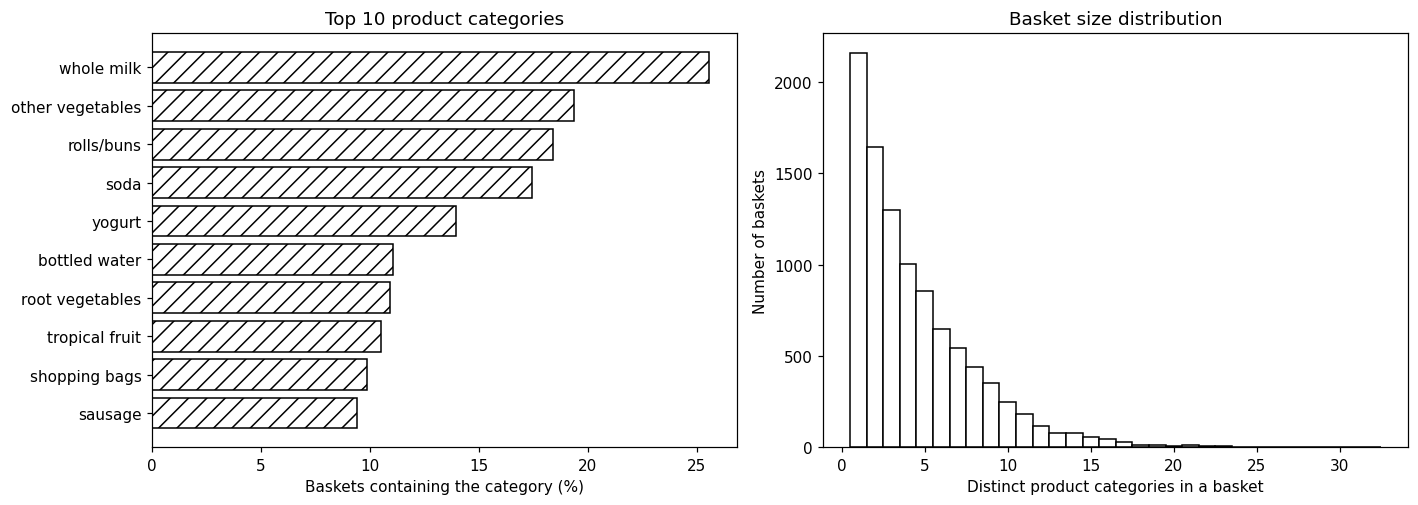

In [6]:
item_stats = pd.DataFrame({"basket_count": X.sum(axis=0).astype(int),
                           "support": X.mean(axis=0)})
item_stats.index.name = "product"
item_stats = item_stats.sort_values(["basket_count"], ascending=False)
basket_sizes = X.sum(axis=1).astype(int)
display(item_stats.head(10).assign(support_percent=lambda d: (100*d.support).round(2)))
display(basket_sizes.describe().rename("Distinct categories per basket").to_frame())
print(f"Whole milk appears in {int(X['whole milk'].sum()):,} baskets "
      f"({X['whole milk'].mean():.2%}).")

def save_show(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / name, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.7))
top = item_stats.head(10).iloc[::-1]
axes[0].barh(top.index, top.support * 100, facecolor="white", edgecolor="black", hatch="//")
axes[0].set_xlabel("Baskets containing the category (%)")
axes[0].set_title("Top 10 product categories")
axes[1].hist(basket_sizes, bins=np.arange(.5, basket_sizes.max()+1.5),
             color="white", edgecolor="black")
axes[1].set_xlabel("Distinct product categories in a basket")
axes[1].set_ylabel("Number of baskets")
axes[1].set_title("Basket size distribution")
save_show(fig, "01_data_overview.png")

## Step 7 — Mine frequent itemsets with two algorithms

**Purpose:** Implement Apriori and FP-Growth on identical inputs with the same support threshold.

**What the code does:** Apriori grows candidates and prunes any whose subsets are infrequent. FP-Growth uses a shared-prefix tree and conditional pattern growth. Time each method, normalise its output to itemset/support mappings, and verify identical patterns and numerically equal supports. A `frozenset` ignores product ordering.

**Expected output and interpretation:** 333 frequent itemsets from each method at 1% support, measured times, and a readable itemset table. Itemsets include single products and larger combinations; they are not yet recommendations.

In [7]:
t0 = perf_counter()
freq_apriori = apriori(X, min_support=MIN_SUPPORT, use_colnames=True)
apriori_seconds = perf_counter() - t0

t0 = perf_counter()
freq_fp = fpgrowth(X, min_support=MIN_SUPPORT, use_colnames=True)
fp_seconds = perf_counter() - t0

def itemset_map(frame):
    return {frozenset(row.itemsets): float(row.support)
            for row in frame.itertuples(index=False)}
map_ap = itemset_map(freq_apriori)
map_fp = itemset_map(freq_fp)
assert map_ap.keys() == map_fp.keys(), "Algorithms disagree on itemsets"
assert all(np.isclose(map_ap[key], map_fp[key]) for key in map_ap)

first_run = pd.DataFrame({"algorithm": ["Apriori", "FP-Growth"],
                          "frequent_itemsets": [len(freq_apriori), len(freq_fp)],
                          "mining_seconds": [apriori_seconds, fp_seconds]})
display(first_run.round(4))
itemset_view = freq_fp.copy()
itemset_view["products"] = itemset_view.itemsets.map(lambda s: " + ".join(sorted(s)))
itemset_view["size"] = itemset_view.itemsets.map(len)
itemset_view["basket_count"] = np.rint(itemset_view.support*N).astype(int)
display(itemset_view.sort_values(["size", "support"], ascending=[False, False])
        [["products", "size", "basket_count", "support"]].head(12))
print("PASS: both algorithms returned the same itemsets and supports.")

PASS: both algorithms returned the same itemsets and supports.


,algorithm,frequent_itemsets,mining_seconds
0,Apriori,333,0.0481
1,FP-Growth,333,0.0964


,products,size,basket_count,support
244,other vegetables + root vegetables + whole milk,3,228,0.023183
114,other vegetables + whole milk + yogurt,3,219,0.022267
158,other vegetables + rolls/buns + whole milk,3,176,0.017895
124,other vegetables + tropical fruit + whole milk,3,168,0.017082
112,rolls/buns + whole milk + yogurt,3,153,0.015557
122,tropical fruit + whole milk + yogurt,3,149,0.015150
299,other vegetables + whipped/sour cream + whole milk,3,144,0.014642
247,root vegetables + whole milk + yogurt,3,143,0.014540
193,other vegetables + soda + whole milk,3,137,0.013930
142,other vegetables + pip fruit + whole milk,3,133,0.013523


## Step 8 — Generate and filter association rules

**Purpose:** Convert frequent itemsets into directional antecedent → consequent relationships.

**What the code does:** Generate rules with confidence at least 25%. Handle the library’s optional `num_itemsets` argument, compare rule identities across algorithms, and format support counts and percentages. Keep lift > 1 for positive associations and single-product consequents for the recommendation function.

**Expected output and interpretation:** 170 baseline rules and 169 positive rules for this dataset/configuration. Ranking considers lift, confidence and supporting count. Confidence is directional; itemset support is not.

In [8]:
def generate_rules(itemsets, total_baskets, confidence):
    # mlxtend versions differ in whether num_itemsets is exposed/required.
    options = {"metric": "confidence", "min_threshold": confidence}
    if "num_itemsets" in inspect.signature(association_rules).parameters:
        options["num_itemsets"] = total_baskets
    if itemsets.empty or not itemsets.itemsets.map(len).ge(2).any():
        return pd.DataFrame(columns=["antecedents", "consequents", "support",
                                     "confidence", "lift", "antecedent support",
                                     "consequent support"])
    return association_rules(itemsets, **options)

rules_all = generate_rules(freq_fp, N, MIN_CONFIDENCE)
rules_ap = generate_rules(freq_apriori, N, MIN_CONFIDENCE)
def rule_keys(frame):
    return set(zip(frame.antecedents, frame.consequents))
assert rule_keys(rules_all) == rule_keys(rules_ap)
assert not rules_all.empty, "No rules found at baseline settings"
rules_positive = rules_all.loc[rules_all.lift > 1].copy()
recommendation_rules = rules_positive.loc[
    rules_positive.consequents.map(len).eq(1)].copy()

def rule_table(frame, total=N):
    result = pd.DataFrame(index=frame.index)
    result["antecedent"] = frame.antecedents.map(lambda s: " + ".join(sorted(s)))
    result["consequent"] = frame.consequents.map(lambda s: " + ".join(sorted(s)))
    result["support_count"] = np.rint(frame.support*total).astype(int)
    result["support_percent"] = 100*frame.support
    result["confidence_percent"] = 100*frame.confidence
    result["lift"] = frame.lift
    return result.sort_values(["lift", "confidence_percent", "support_count", "antecedent", "consequent"],
                              ascending=[False, False, False, True, True]).reset_index(drop=True)

readable_rules = rule_table(rules_all)
print(f"All rules meeting confidence >= {MIN_CONFIDENCE:.0%}: {len(rules_all)}")
print(f"Positive rules (lift > 1): {len(rules_positive)}")
print(f"Positive single-consequent rules for recommendations: {len(recommendation_rules)}")
display(readable_rules.head(10).round(3))

All rules meeting confidence >= 25%: 170
Positive rules (lift > 1): 169
Positive single-consequent rules for recommendations: 169


,antecedent,consequent,support_count,support_percent,confidence_percent,lift
0,citrus fruit + other vegetables,root vegetables,102,1.037,35.915,3.295
1,other vegetables + tropical fruit,root vegetables,121,1.230,34.278,3.145
2,beef,root vegetables,171,1.739,33.140,3.040
3,citrus fruit + root vegetables,other vegetables,102,1.037,58.621,3.030
4,root vegetables + tropical fruit,other vegetables,121,1.230,58.454,3.021
5,other vegetables + whole milk,root vegetables,228,2.318,30.978,2.842
6,curd + whole milk,yogurt,99,1.007,38.521,2.761
7,other vegetables + yogurt,root vegetables,127,1.291,29.742,2.729
8,other vegetables + yogurt,tropical fruit,121,1.230,28.337,2.701
9,other vegetables + rolls/buns,root vegetables,120,1.220,28.640,2.628


## Step 9 — Interpret the highest-ranked rule

**Purpose:** Translate one calculated association into ordinary language.

**What the code does:** Read the top row of the actual rule table and display its antecedent, consequent, supporting count, support, confidence and lift. Values come from the current analysis, not a fixed reference example.

**Expected output and interpretation:** The leading rule links citrus fruit plus other vegetables to root vegetables: 102 baskets, about 1.04% support, 35.9% confidence and 3.30 lift. Lift is an association ratio, not a predicted sales multiplier.

In [9]:
# This explanation uses the highest-ranked rule from the ACTUAL run, not a typed result.
leading = readable_rules.iloc[0]
display(Markdown(
    f"### Interpretation of the leading rule\n"
    f"**{leading['antecedent']} → {leading['consequent']}**\n\n"
    f"- The complete combination occurs in **{int(leading['support_count'])} baskets** "
    f"(**{leading['support_percent']:.2f}%** of all transactions).\n"
    f"- Among antecedent baskets, **{leading['confidence_percent']:.1f}%** also contain the consequent.\n"
    f"- The consequent is **{leading['lift']:.2f} times as common** in those baskets as overall.\n\n"
    f"**Decision:** shortlist a targeted cross-promotion experiment. "
    f"This does not establish a sales increase or a causal effect."
))

### Interpretation of the leading rule
**citrus fruit + other vegetables → root vegetables**

- The complete combination occurs in **102 baskets** (**1.04%** of all transactions).
- Among antecedent baskets, **35.9%** also contain the consequent.
- The consequent is **3.30 times as common** in those baskets as overall.

**Decision:** shortlist a targeted cross-promotion experiment. This does not establish a sales increase or a causal effect.

## Step 10 — Verify rule metrics from transaction counts

**Purpose:** Independently check that the mining library’s metrics have the intended meaning.

**What the code does:** Require all antecedent products and all consequent products using `.all(axis=1)`. Count baskets containing A, B and both. Calculate support = count(A ∪ B)/N; confidence = count(A ∪ B)/count(A); lift = confidence/support(B). Compare all baseline rules with tolerance for floating-point rounding.

**Expected output and interpretation:** A direct-count table and confirmation that all 170 rule metrics match. Undefined denominators return NaN rather than an invented value. Antecedent and consequent must be disjoint.

In [10]:
def direct_metrics(matrix, antecedent, consequent):
    a = matrix.loc[:, sorted(antecedent)].all(axis=1)
    b = matrix.loc[:, sorted(consequent)].all(axis=1)
    both = a & b
    support = float(both.mean())
    confidence = float(both.sum()/a.sum()) if a.sum() else np.nan
    lift = confidence/float(b.mean()) if b.sum() else np.nan
    return {"antecedent_count": int(a.sum()), "consequent_count": int(b.sum()),
            "joint_count": int(both.sum()), "support": support,
            "confidence": confidence, "lift": lift}

for row in rules_all.itertuples(index=False):
    measured = direct_metrics(X, row.antecedents, row.consequents)
    assert np.allclose([measured["support"], measured["confidence"], measured["lift"]],
                       [row.support, row.confidence, row.lift])
    assert measured["joint_count"] >= MIN_COUNT
    assert row.antecedents.isdisjoint(row.consequents)

top_raw = rules_all.sort_values(["lift", "confidence"], ascending=False).iloc[0]
display(pd.Series(direct_metrics(X, top_raw.antecedents, top_raw.consequents),
                  name="Independently verified").to_frame())
print(f"PASS: all {len(rules_all)} baseline rules verified against transaction counts.")

PASS: all 170 baseline rules verified against transaction counts.


,Independently verified
antecedent_count,284.000000
consequent_count,1072.000000
joint_count,102.000000
support,0.010371
confidence,0.359155
lift,3.295045


## Step 11 — Demonstrate metric calculations with eight baskets

**Purpose:** Provide a small manually countable example that explains the measures.

**What the code does:** Encode eight illustrative baskets separately from the real data and calculate Eggs → Milk, Butter → Bread, and Bread → Milk. This small example is educational; it is not additional Kaggle evidence.

**Expected output and interpretation:** Eggs → Milk: 37.5% support, 100% confidence and 1.33 lift. Bread → Milk: 50% support, 66.7% confidence and 0.89 lift. High confidence can coexist with negative relative association.

In [11]:
toy_baskets = [
    ["bread", "butter", "milk"], ["bread", "butter"],
    ["bread", "milk", "eggs"], ["bread", "butter", "milk", "jam"],
    ["milk", "eggs"], ["bread", "butter", "jam"],
    ["bread", "milk"], ["butter", "milk", "eggs"]
]
te_toy = TransactionEncoder()
X_toy = pd.DataFrame(te_toy.fit(toy_baskets).transform(toy_baskets), columns=te_toy.columns_)
display(pd.DataFrame({"basket_id": range(1,9), "items": [", ".join(b) for b in toy_baskets]}))
toy_rows = []
for a, b in [("eggs","milk"), ("butter","bread"), ("bread","milk")]:
    v = direct_metrics(X_toy, {a}, {b})
    toy_rows.append({"rule": f"{a} → {b}", "support_%": v["support"]*100,
                     "confidence_%": v["confidence"]*100, "lift": v["lift"]})
display(pd.DataFrame(toy_rows).round(3))
assert np.isclose(toy_rows[0]["lift"], 4/3)
assert toy_rows[2]["lift"] < 1

,basket_id,items
0,1,"bread, butter, milk"
1,2,"bread, butter"
2,3,"bread, milk, eggs"
3,4,"bread, butter, milk, jam"
4,5,"milk, eggs"
5,6,"bread, butter, jam"
6,7,"bread, milk"
7,8,"butter, milk, eggs"


,rule,support_%,confidence_%,lift
0,eggs → milk,37.5,100.000,1.333
1,butter → bread,50.0,80.000,1.067
2,bread → milk,50.0,66.667,0.889


## Step 12 — Visualise the evaluated associations

**Purpose:** Show rule strength, reach and product-pair co-occurrence in a readable form.

**What the code does:** Build a top-10 lift chart with rule IDs and an independence baseline at lift = 1. Plot support against confidence, with marker area increasing with lift. For six categories, convert the Boolean matrix to integer before `Z.T @ Z` to count co-occurrences correctly.

**Expected output and interpretation:** Three PNG files in `Results/`: ranked lifts, support-confidence scatter and labelled pair-support matrix. The matrix diagonal shows individual support. A pair count is not a causal or multi-item directional rule.

,rule_id,antecedent,consequent,support_count,confidence_percent,lift
0,R1,citrus fruit + other vegetables,root vegetables,102,35.915,3.295
1,R2,other vegetables + tropical fruit,root vegetables,121,34.278,3.145
2,R3,beef,root vegetables,171,33.140,3.040
3,R4,citrus fruit + root vegetables,other vegetables,102,58.621,3.030
4,R5,root vegetables + tropical fruit,other vegetables,121,58.454,3.021
5,R6,other vegetables + whole milk,root vegetables,228,30.978,2.842
6,R7,curd + whole milk,yogurt,99,38.521,2.761
7,R8,other vegetables + yogurt,root vegetables,127,29.742,2.729
8,R9,other vegetables + yogurt,tropical fruit,121,28.337,2.701
9,R10,other vegetables + rolls/buns,root vegetables,120,28.640,2.628


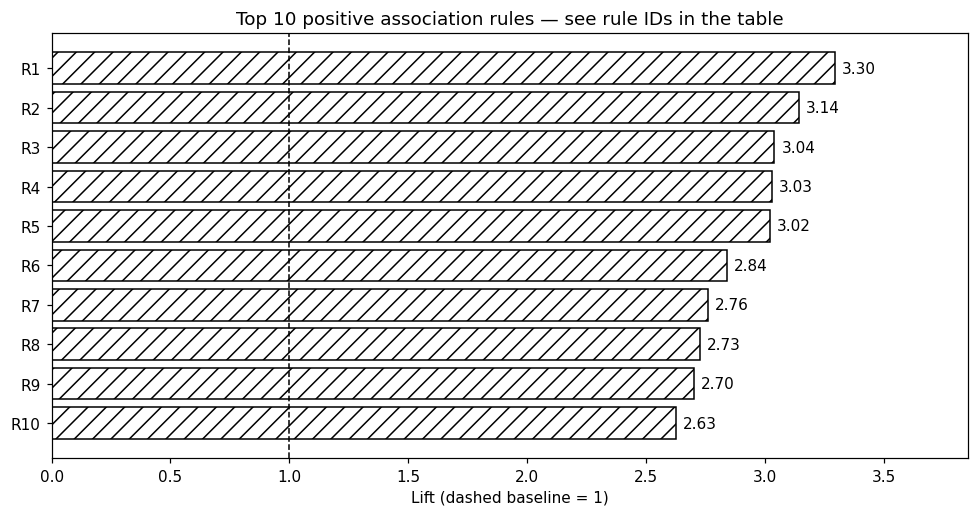

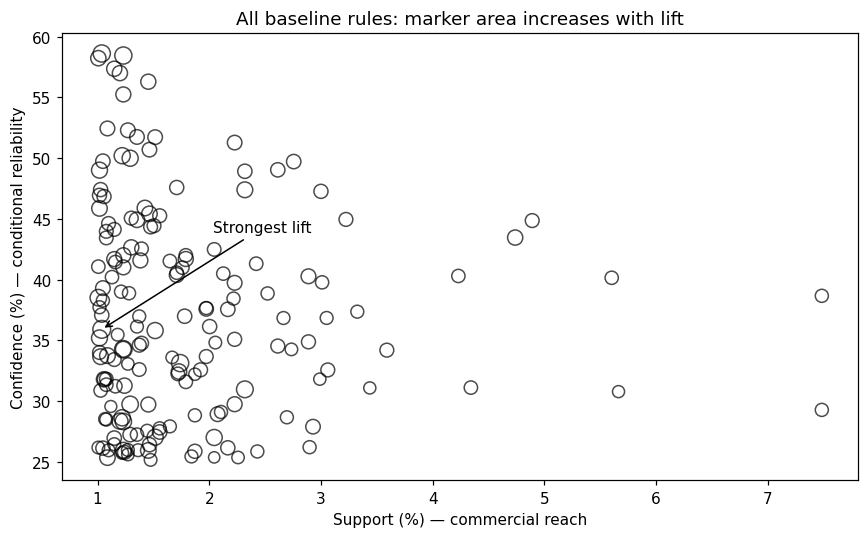

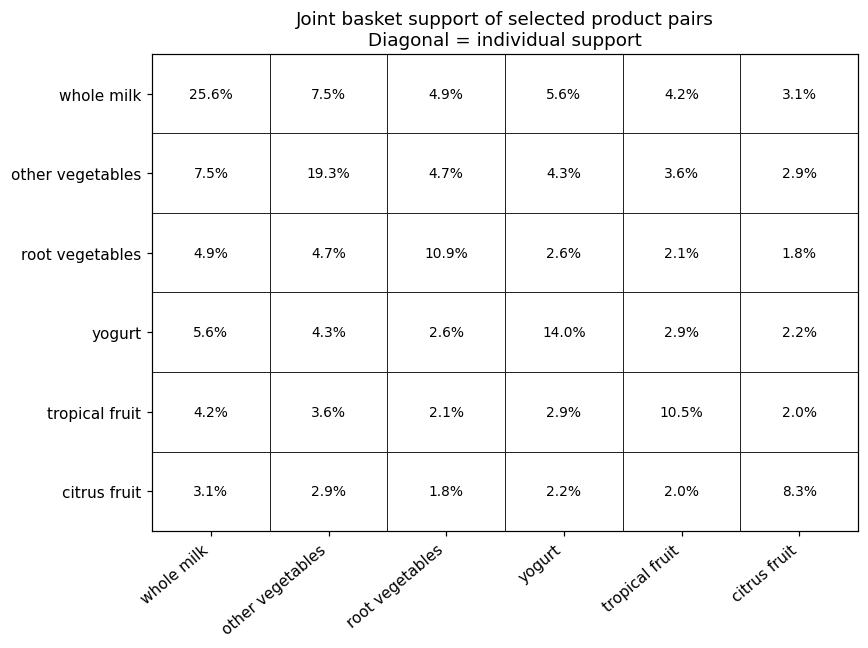

In [12]:
top10 = rule_table(rules_positive).head(10).copy()
top10["rule_id"] = [f"R{i}" for i in range(1, len(top10)+1)]
display(top10[["rule_id", "antecedent", "consequent", "support_count",
               "confidence_percent", "lift"]].round(3))
fig, ax = plt.subplots(figsize=(9, 4.8))
plot = top10.iloc[::-1]
ax.barh(plot.rule_id, plot.lift, color="white", edgecolor="black", hatch="//")
ax.axvline(1, color="black", linestyle="--", linewidth=1)
for i, v in enumerate(plot.lift): ax.text(v+.03, i, f"{v:.2f}", va="center")
ax.set_xlim(0, max(plot.lift)*1.17)
ax.set_xlabel("Lift (dashed baseline = 1)")
ax.set_title("Top 10 positive association rules — see rule IDs in the table")
save_show(fig, "02_top_rules_lift.png")

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(rules_all.support*100, rules_all.confidence*100,
           s=20+35*rules_all.lift, facecolors="none", edgecolors="black", alpha=.7)
ax.set_xlabel("Support (%) — commercial reach")
ax.set_ylabel("Confidence (%) — conditional reliability")
ax.set_title("All baseline rules: marker area increases with lift")
ax.annotate("Strongest lift", xy=(leading.support_percent, leading.confidence_percent),
            xytext=(leading.support_percent+1, leading.confidence_percent+8),
            arrowprops={"arrowstyle": "->", "color": "black"})
save_show(fig, "03_support_confidence.png")

selected = ["whole milk", "other vegetables", "root vegetables", "yogurt",
            "tropical fruit", "citrus fruit"]
# Convert to integer BEFORE multiplication: Boolean dot does not give counts.
Z = X[selected].to_numpy(dtype=np.int64)
pair_support = (Z.T @ Z) / N * 100
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_xlim(-.5, len(selected)-.5); ax.set_ylim(len(selected)-.5, -.5)
ax.set_xticks(range(len(selected)), selected, rotation=40, ha="right")
ax.set_yticks(range(len(selected)), selected)
for i in range(len(selected)):
    for j in range(len(selected)):
        ax.add_patch(plt.Rectangle((j-.5,i-.5),1,1,facecolor="white",edgecolor="black",linewidth=.5))
        ax.text(j, i, f"{pair_support[i,j]:.1f}%", ha="center",va="center",fontsize=9)
ax.set_title("Joint basket support of selected product pairs\nDiagonal = individual support")
save_show(fig, "04_pair_support_matrix.png")

## Step 13 — Benchmark algorithms and examine thresholds

**Purpose:** Compare computational efficiency fairly and inspect sensitivity to analysis settings.

**What the code does:** Run each algorithm three times and report median/minimum/maximum mining time. Verify output equivalence for every repetition. Then compare support 0.5%, 1%, 2% and confidence 25%, 40%, 60%. Preprocessing and rule-generation times are outside the mining benchmark.

**Expected output and interpretation:** A benchmark table and nine threshold combinations. Results depend on this machine and dataset; neither algorithm is assumed to be universally faster. More rules do not automatically mean better business decisions.

In [13]:
benchmark_rows = []
for name, function in [("Apriori", apriori), ("FP-Growth", fpgrowth)]:
    elapsed = []
    for repetition in range(3):
        t0 = perf_counter()
        output = function(X, min_support=MIN_SUPPORT, use_colnames=True)
        elapsed.append(perf_counter()-t0)
        observed = itemset_map(output)
        assert observed.keys() == map_fp.keys()
        assert all(np.isclose(observed[key], map_fp[key]) for key in map_fp)
    benchmark_rows.append({"algorithm": name, "median_mining_seconds": float(np.median(elapsed)),
                           "min_seconds": min(elapsed), "max_seconds": max(elapsed),
                           "itemsets": len(output), "repeats": len(elapsed)})
benchmark = pd.DataFrame(benchmark_rows)
display(benchmark.round(4))

sensitivity_rows = []
for support in [.005, .01, .02]:
    freq = fpgrowth(X, min_support=support, use_colnames=True)
    candidate_rules = generate_rules(freq, N, .25)
    for confidence in [.25, .40, .60]:
        keep = candidate_rules[candidate_rules.confidence >= confidence]
        sensitivity_rows.append({"min_support": support, "min_confidence": confidence,
                                  "itemsets": len(freq), "rules": len(keep),
                                  "positive_rules": int((keep.lift>1).sum())})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity)

,algorithm,median_mining_seconds,min_seconds,max_seconds,itemsets,repeats
0,Apriori,0.0466,0.0456,0.0494,333,3
1,FP-Growth,0.0819,0.0753,0.1751,333,3


,min_support,min_confidence,itemsets,rules,positive_rules
0,0.005,0.25,1001,673,672
1,0.005,0.40,1001,270,270
2,0.005,0.60,1001,22,22
3,0.010,0.25,333,170,169
4,0.010,0.40,333,62,62
5,0.010,0.60,333,0,0
6,0.020,0.25,122,49,48
7,0.020,0.40,122,15,15
8,0.020,0.60,122,0,0


## Step 14 — Check rules on held-out baskets

**Purpose:** Examine whether associations discovered on one subset persist in another subset.

**What the code does:** Use a seeded random 80/20 split. Mine NEW rules from the discovery subset only, select ten positive single-consequent rules, and recompute their metrics on validation baskets. The screening flag requires positive lift, sufficient validation support and confidence at least 25%.

**Expected output and interpretation:** 7,868 discovery baskets and 1,967 validation baskets with rule comparisons. This is an exploratory stability screen, not a classification accuracy score, a formal significance test, or proof of future-season performance.

In [14]:
rng = np.random.default_rng(SEED)
indices = rng.permutation(N)
cut = int(.8*N)
X_discovery = X.iloc[indices[:cut]].copy()
X_validation = X.iloc[indices[cut:]].copy()
freq_discovery = fpgrowth(X_discovery, min_support=MIN_SUPPORT, use_colnames=True)
rules_discovery = generate_rules(freq_discovery, len(X_discovery), MIN_CONFIDENCE)
shortlist = rules_discovery.loc[
    (rules_discovery.lift > 1) & rules_discovery.consequents.map(len).eq(1)
].sort_values(["lift", "confidence"], ascending=False).head(10)
validation_rows = []
for row in shortlist.itertuples(index=False):
    v = direct_metrics(X_validation, row.antecedents, row.consequents)
    validation_rows.append({
        "rule": " + ".join(sorted(row.antecedents))+" → "+" + ".join(sorted(row.consequents)),
        "discovery_lift": row.lift, "validation_lift": v["lift"],
        "validation_joint_count": v["joint_count"],
        "validation_confidence_%": v["confidence"]*100,
        "screen_pass": bool(v["lift"]>1 and v["joint_count"]>=ceil(MIN_SUPPORT*len(X_validation))
                            and v["confidence"]>=MIN_CONFIDENCE)
    })
validation = pd.DataFrame(validation_rows)
print(f"Discovery baskets: {len(X_discovery):,}; validation baskets: {len(X_validation):,}")
display(validation.round(3))
print("Interpretation: metric changes show sampling sensitivity, not measured business impact.")

Discovery baskets: 7,868; validation baskets: 1,967
Interpretation: metric changes show sampling sensitivity, not measured business impact.


,rule,discovery_lift,validation_lift,validation_joint_count,validation_confidence_%,screen_pass
0,citrus fruit + other vegetables → root vegetables,3.233,3.545,22,39.286,True
1,citrus fruit + root vegetables → other vegetables,3.174,2.587,22,51.163,True
2,other vegetables + tropical fruit → root vegetables,3.071,3.398,29,37.662,True
3,root vegetables + tropical fruit → other vegetables,3.026,2.993,29,59.184,True
4,beef → root vegetables,2.986,3.212,42,35.593,True
5,whipped/sour cream + whole milk → root vegetables,2.964,1.529,10,16.949,False
6,other vegetables + whole milk → root vegetables,2.936,2.472,40,27.397,True
7,other vegetables + yogurt → root vegetables,2.847,2.256,21,25.000,True
8,curd + whole milk → yogurt,2.713,2.978,19,40.426,False
9,other vegetables + yogurt → tropical fruit,2.663,2.856,25,29.762,True


## Step 15 — Define the basket recommendation function

**Purpose:** Turn evaluated association rules into explainable product suggestions.

**What the code does:** Normalise the input basket and reject empty/unknown products. Require the complete antecedent to be a subset of the basket, exclude products already present, and retain rules exceeding the configured lift cutoff and meeting confidence. Rank by lift, confidence and support; show the strongest matching rule per product.

**Expected output and interpretation:** This cell defines functions and may have no visible output. Later cells call them. Confidence describes a historical group of baskets; it is not a calibrated individual purchase probability.

In [15]:
RECOMMENDATION_COLUMNS = ["suggested_product", "matched_antecedent", "support_count",
                          "confidence_percent", "lift"]

def recommend_products(basket_items, top_n=5, min_confidence=MIN_CONFIDENCE,
                       min_lift=1.0, rule_frame=None):
    if isinstance(basket_items, str):
        basket_items = next(csv.reader([basket_items]))
    selected = {str(item).strip().lower() for item in basket_items if str(item).strip()}
    if not selected:
        raise ValueError("Add at least one product from the dataset.")
    unknown = selected - set(X.columns)
    if unknown:
        raise ValueError("Unknown product(s): "+", ".join(sorted(unknown))+
                         ". Use exact category names from the product list.")
    frame = recommendation_rules if rule_frame is None else rule_frame
    matches = []
    for row in frame.itertuples(index=False):
        if len(row.consequents)!=1 or not row.antecedents.issubset(selected):
            continue
        product = next(iter(row.consequents))
        if product in selected or row.lift <= min_lift or row.confidence < min_confidence:
            continue
        matches.append({"suggested_product": product,
                        "matched_antecedent": " + ".join(sorted(row.antecedents)),
                        "support_count": int(round(row.support*N)),
                        "confidence_percent": row.confidence*100, "lift": row.lift})
    if not matches:
        return pd.DataFrame(columns=RECOMMENDATION_COLUMNS)
    return (pd.DataFrame(matches)
            .sort_values(["lift", "confidence_percent", "support_count", "suggested_product"],
                         ascending=[False, False, False, True])
            .drop_duplicates("suggested_product").head(top_n).reset_index(drop=True))

def explain_basket(items):
    print("Current basket:", ", ".join(items))
    suggestions = recommend_products(items)
    if suggestions.empty:
        print("No matching positive rule at the current thresholds. Try a different basket.")
    else:
        display(suggestions.round(3))
        first = suggestions.iloc[0]
        print(f"Recommendation: {first.suggested_product!r} because the basket "
              f"contains {first.matched_antecedent!r}. The historical rule has "
              f"{first.confidence_percent:.1f}% confidence and lift {first.lift:.2f}.")
    return suggestions

## Step 16 — Run a sample recommendation

**Purpose:** Demonstrate the business application with an editable shopping basket.

**What the code does:** Set `DEMO_BASKET = ["curd", "whole milk"]` and call `explain_basket`. Change only this list and rerun the cell for another example, such as `["beef"]` or `["citrus fruit", "other vegetables"]`. Use exact category names from the dataset.

**Expected output and interpretation:** Ranked missing products and the supporting rule. Yogurt leads for curd plus whole milk, with approximately 38.5% confidence and 2.76 lift. No matching rule is a valid outcome.

In [16]:
# LIVE DEMO: change only this list and rerun this cell.
DEMO_BASKET = ["curd", "whole milk"]
demo_suggestions = explain_basket(DEMO_BASKET)

# Other example inputs: ["beef"] or ["citrus fruit", "other vegetables"]
# For exact available names, run: print("\n".join(sorted(X.columns)))

Current basket: curd, whole milk
Recommendation: 'yogurt' because the basket contains 'curd + whole milk'. The historical rule has 38.5% confidence and lift 2.76.


,suggested_product,matched_antecedent,support_count,confidence_percent,lift
0,yogurt,curd + whole milk,99,38.521,2.761
1,other vegetables,curd,169,32.252,1.667


## Step 17 — Offer an optional interactive product picker

**Purpose:** Allow product selection and recommendation through controls instead of editing Python.

**What the code does:** Create a multi-select category list, a Recommend button and an output area. Register a callback that clears previous output and evaluates the selected basket. Show invalid-input messages as text. If ipywidgets is unavailable, use the ordinary editable list from Step 16.

**Expected output and interpretation:** A selector and button in a compatible notebook frontend. Saved notebook outputs are a static snapshot; rerun this cell to activate the live widget.

In [17]:
try:
    import ipywidgets as widgets
    picker = widgets.SelectMultiple(options=sorted(X.columns), value=tuple(DEMO_BASKET),
                                    description="Basket", rows=10,
                                    layout=widgets.Layout(width="520px"))
    button = widgets.Button(description="Recommend", button_style="")
    widget_output = widgets.Output()
    def on_recommend(_):
        with widget_output:
            widget_output.clear_output(wait=True)
            try:
                explain_basket(list(picker.value))
            except ValueError as error:
                print(error)
    button.on_click(on_recommend)
    display(widgets.VBox([picker, button, widget_output]))
    print("Use Ctrl/Cmd-click for several products, then click Recommend.")
except ImportError:
    print("Optional picker unavailable. Edit DEMO_BASKET and rerun the previous cell.")

Use Ctrl/Cmd-click for several products, then click Recommend.


## Step 18 — Check recommendation correctness

**Purpose:** Verify important edge cases without depending on which real rule ranks first.

**What the code does:** Construct one controlled test rule, require both antecedent products, exclude an already-purchased consequent, reject empty/unknown inputs, and permit a valid no-match result. Check real examples to ensure recommendations never overlap with products already in the basket.

**Expected output and interpretation:** A PASS message. The controlled rule’s numbers are deliberately chosen test values, not findings from the grocery dataset.

In [18]:
# Controlled rules isolate logic from whatever happens to rank highest in the real data.
controlled_rules = pd.DataFrame([
    {"antecedents": frozenset({"curd", "whole milk"}), "consequents": frozenset({"yogurt"}),
     "support": .02, "confidence": .5, "lift": 2.0}])
assert recommend_products(["curd"], rule_frame=controlled_rules).empty
assert recommend_products(["curd", "whole milk"], rule_frame=controlled_rules).suggested_product.tolist()==["yogurt"]
assert recommend_products(["curd", "whole milk", "yogurt"], rule_frame=controlled_rules).empty
for invalid in [[], ["this product does not exist"]]:
    try:
        recommend_products(invalid)
        raise AssertionError("Invalid input was accepted")
    except ValueError:
        pass
assert recommend_products(["whole milk"], rule_frame=controlled_rules).empty
for test_basket in [["beef"], ["curd", "whole milk"], ["citrus fruit", "other vegetables"]]:
    result = recommend_products(test_basket)
    assert not (set(result.suggested_product) & set(test_basket))
print("PASS: recommendation matching and input validation checks passed.")

PASS: recommendation matching and input validation checks passed.


## Step 19 — Export results and summarise the implementation

**Purpose:** Save the evidence needed for GitHub, the POC, presentation and further review.

**What the code does:** Write rule/itemset/frequency tables, timing, sensitivity, validation and recommendations to CSV. Save audit, package versions and run metadata to JSON. Export cleaned baskets separately from the original input. Save source attribution and checksum. Zip only the Results directory; store the ZIP beside it to avoid including it in itself.

**Expected output and interpretation:** `Results/` contains CSV, JSON, TXT and PNG outputs. `Market_Basket_Results.zip` appears in the project folder. The final summary reports actual counts and verified checks. No financial uplift is claimed because no store trial was conducted.

In [19]:
# Save machine-readable results without Python frozenset objects.
readable_rules.to_csv(OUTPUT_DIR/"all_association_rules.csv", index=False)
rule_table(rules_positive).to_csv(OUTPUT_DIR/"positive_rules.csv", index=False)
itemset_view.drop(columns="itemsets").to_csv(OUTPUT_DIR/"frequent_itemsets.csv", index=False)
item_stats.to_csv(OUTPUT_DIR/"item_frequencies.csv")
benchmark.to_csv(OUTPUT_DIR/"algorithm_benchmark.csv", index=False)
sensitivity.to_csv(OUTPUT_DIR/"threshold_sensitivity.csv", index=False)
validation.to_csv(OUTPUT_DIR/"holdout_validation.csv", index=False)
demo_suggestions.to_csv(OUTPUT_DIR/"demo_recommendations.csv", index=False)
(OUTPUT_DIR/"cleaning_audit.json").write_text(json.dumps(cleaning_audit,indent=2),encoding="utf-8")
(OUTPUT_DIR/"environment_versions.json").write_text(json.dumps(VERSIONS,indent=2),encoding="utf-8")
summary = {
    "dataset": "Groceries", "dataset_kaggle_url": DATA_SOURCE_URL, "loaded_file": selected_filename, "input_format": input_format, "sha256": DATA_SHA256,
    "baskets": N, "categories": len(X.columns), "min_support": MIN_SUPPORT,
    "min_support_count": MIN_COUNT, "min_confidence": MIN_CONFIDENCE,
    "frequent_itemsets": len(freq_fp), "baseline_rules": len(rules_all),
    "positive_rules": len(rules_positive), "recommendation_rules": len(recommendation_rules),
    "algorithms_equivalent": bool(map_ap.keys()==map_fp.keys() and all(np.isclose(map_ap[key],map_fp[key]) for key in map_ap)),
    "validation_note": "Separate 80/20 discovery and validation experiment; no business trial performed"
}
(OUTPUT_DIR/"run_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
(OUTPUT_DIR/"dataset_source.txt").write_text(
    "Canonical documentation: https://michael.hahsler.net/arules/reference/Groceries.html\n"
    "Kaggle dataset: "+DATA_SOURCE_URL+"\nSHA-256: "+DATA_SHA256+"\n",encoding="utf-8")

# Snapshot file names before archiving; the ZIP is outside Results/ to avoid self-inclusion.
with (OUTPUT_DIR/'cleaned_baskets.csv').open('w', newline='', encoding='utf-8') as handle:
    csv.writer(handle).writerows(baskets)
import shutil
archive = shutil.make_archive(str(PROJECT_DIR/'Market_Basket_Results'), "zip", OUTPUT_DIR)
display(Markdown(
    f"## IMPLEMENTATION COMPLETED\n"
    f"- **Data:** {N:,} real baskets, {len(X.columns)} categories.\n"
    f"- **Cleaning:** {cleaning_audit['tokens_normalised']} tokens normalised; "
    f"{cleaning_audit['empty_baskets_excluded']} empty baskets excluded.\n"
    f"- **Mining:** {len(freq_fp)} frequent itemsets; Apriori and FP-Growth agree.\n"
    f"- **Rules:** {len(rules_all)} baseline rules; {len(rules_positive)} with positive lift.\n"
    f"- **Checks:** all baseline metrics independently verified; recommendation logic checked.\n"
    f"- **Application:** edit DEMO_BASKET or use the optional picker.\n"
    f"- **Exports:** `{OUTPUT_DIR}` and `{Path(archive).name}`.\n\n"
    f"**Conclusion:** We can discover and explain retail associations. "
    f"Sales improvement must be evaluated in a controlled business trial."
))
display(pd.DataFrame({"exported_file": [p.name for p in sorted(OUTPUT_DIR.iterdir())]}))

## IMPLEMENTATION COMPLETED
- **Data:** 9,835 real baskets, 169 categories.
- **Cleaning:** 408 tokens normalised; 0 empty baskets excluded.
- **Mining:** 333 frequent itemsets; Apriori and FP-Growth agree.
- **Rules:** 170 baseline rules; 169 with positive lift.
- **Checks:** all baseline metrics independently verified; recommendation logic checked.
- **Application:** edit DEMO_BASKET or use the optional picker.
- **Exports:** `/workspace/scratch/5db1f46b376e/tmp/market_basket/submission_check/CA1_CA2_Market_Basket_Analysis/Results` and `Market_Basket_Results.zip`.

**Conclusion:** We can discover and explain retail associations. Sales improvement must be evaluated in a controlled business trial.

,exported_file
0,01_data_overview.png
1,02_top_rules_lift.png
2,03_support_confidence.png
3,04_pair_support_matrix.png
4,algorithm_benchmark.csv
...,...
12,holdout_validation.csv
13,item_frequencies.csv
14,positive_rules.csv
15,run_summary.json


## Insights and final business decision

The strongest reference patterns point to produce combinations and dairy cross-selling. Review reach, lift, stability and operational feasibility before choosing an action. Popularity alone is insufficient, and high lift on a narrow combination may justify only a targeted experiment.

| Analytical finding | Candidate decision | Business evaluation required |
|---|---|---|
| Positive produce associations | Test coordinated displays or relevant suggestions | Compare basket value and profit against a control |
| Curd plus whole milk associated with yogurt | Test a yogurt recommendation or eligible-basket offer | Monitor uptake and profit after discount costs |
| Rules vary with thresholds/samples | Keep a short interpretable, stable shortlist | Revalidate and refresh when data changes |

**Limitations:** One outlet and a short observation period; category-level data; no established price, cost, quantity or customer linkage for this basket representation. Association does not imply causation. A controlled business trial is needed to establish incremental sales or profit.

**CA2 coverage:** This notebook provides dataset loading/preprocessing, two implemented algorithms, generated and evaluated results, appropriate charts, interpreted insights, and a working application tied to the business goal.


## References

- Kaggle download source: https://www.kaggle.com/datasets/irfanasrullah/groceries
- Canonical Groceries description and attribution: https://michael.hahsler.net/arules/reference/Groceries.html
- Agrawal and Srikant (1994), *Fast Algorithms for Mining Association Rules*: https://www.vldb.org/conf/1994/P487.PDF
- Han, Pei and Yin (2000), *Mining Frequent Patterns without Candidate Generation*: https://sigmodrecord.org/2000/06/07/mining-frequent-patterns-without-candidate-generation/
- TransactionEncoder: https://rasbt.github.io/mlxtend/user_guide/preprocessing/TransactionEncoder/
- Apriori: https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/
- FP-Growth: https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/
- Rule metrics: https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/association_rules/

The eight-basket example and controlled recommendation tests are explicitly illustrative; all main analysis results are computed from the selected Kaggle file.
